# Let's see what places have the least amount of water!

## Can't Forget!

In [2]:
import pandas as pd

## Our data

Let's open our dataset here!

Our dataset is "water features" because we want to see what places have the least amount of water features in the hopes that there is a correlation between this and the amount of, and reliability of, showers in that neighborhood

In [4]:
df = pd.read_csv("data.csv")
df

,id,name,control_type,feature_type,inactive,make,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,2004439323,Mellon Square - Cascade Fountain,On/Off,Decorative,False,Water Odyssey,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440814,-79.997823
1,320166810,Ammon Park - Drinking Fountain 01,On/Off,Drinking Fountain,False,Regular Fountain,NaN,Bedford Dwellings,6,5,42003050900,3,5,2,2-5,40.449287,-79.977762
2,2070285666,Kennard Park - Drinking Fountain 04,NaN,Drinking Fountain,False,NaN,NaN,Terrace Village,6,5,42003051000,3,5,2,2-10,40.442990,-79.972578
3,1086485662,Mellon Park - Waves Spray,On/Off,Spray,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Shadyside,8,7,42003070800,2,7,4,3-13,40.454059,-79.915652
4,192771028,Mellon Park - Dump Buckets,On/Off,Spray,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Shadyside,8,7,42003070800,2,7,4,3-13,40.453945,-79.915680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,1948209895,Schenley Park - Drinking Fountain 01_RET 25,On/Off,Drinking Fountain,True,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.440600,-79.948481
284,273620901,Schenley Park - Drinking Fountain 04,On/Off,Drinking Fountain,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.431558,-79.943880
285,1304242824,Schenley Plaza - Drinking Fountain 01,On/Off,Drinking Fountain,False,NaN,https://storage.googleapis.com/pghpa_open_data...,North Oakland,8,4,42003982200,3,4,4,2-7,40.442228,-79.952740
286,1228146070,Schenley Plaza - Drinking Fountain 02,On/Off,Drinking Fountain,False,Haws,https://storage.googleapis.com/pghpa_open_data...,North Oakland,8,4,42003982200,3,4,4,2-7,40.443038,-79.952887


## Analyzing the Data!

Let's see how many times each neighborhood appears in the dataset!

In [6]:
value_counts = df.value_counts("neighborhood")
value_counts

neighborhood
Squirrel Hill South    18
Beechview              13
Troy Hill              13
Highland Park          13
Allegheny Center       12
                       ..
Oakwood                 1
Point Breeze North      1
Strip District          1
Upper Hill              1
Upper Lawrenceville     1
Name: count, Length: 67, dtype: int64

## Let's Make It Interesting!

We beleive that "Decorative" water features mean that there is a surpluss of plumbing and low enough plumbing costs to have enough headroom to use water for decoration, this means we want to especially avoid these places (because of the better plumbing and lower water prices), so we can actually weight these!

In [21]:

df_decor = df[df["feature_type"] == "Decorative"]
df_decor


,id,name,control_type,feature_type,inactive,make,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,2004439323,Mellon Square - Cascade Fountain,On/Off,Decorative,False,Water Odyssey,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440814,-79.997823
94,88935866,Mellon Park Garden Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Point Breeze,9,14,42003140400,2,14,4,2-17,40.452008,-79.918923
95,151651347,Mellon Park Rose Garden Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Point Breeze,9,14,42003140400,2,14,4,2-17,40.451933,-79.917453
113,1828313636,Frick Park Decorative Fountain,On/Off,Decorative,False,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Squirrel Hill South,5,14,42003980300,3,14,4,2-21,40.436624,-79.906842
141,1521781619,Joy of Life Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,East Liberty,9,8,42003111500,2,8,5,3-11,40.460726,-79.926258
161,2041357667,Highland Park Entrance Decorative Fountain,NaN,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Highland Park,7,11,42003980100,2,11,5,3-9,40.479365,-79.915532
193,998600877,Mellon Square Decorative Fountain,On/Off,Decorative,False,Regular Fountain,https://storage.googleapis.com/pghpa_open_data...,Central Business District,1,2,42003020100,1,2,2,1-4,40.440888,-79.997332
233,1085091446,Allegheny Commons Decorative Fountain,Continuous,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Allegheny Center,1,22,42003562700,1,22,1,1-6,40.455807,-80.002990
255,1895367685,Mary Schenley Memorial Fountain,On/Off,Decorative,False,NaN,https://storage.googleapis.com/pghpa_open_data...,Central Oakland,3,4,42003040500,3,4,4,2-11,40.441957,-79.951866


In [26]:
decor_counts = df_decor.value_counts("neighborhood")
decor_counts

neighborhood
Central Business District    2
Point Breeze                 2
Allegheny Center             1
Central Oakland              1
East Liberty                 1
Highland Park                1
Squirrel Hill South          1
Name: count, dtype: int64

In [40]:
weighted_counts = value_counts.add(decor_counts, fill_value=0).sort_values(ascending=False)
weighted_counts

neighborhood
Squirrel Hill South    19.0
Highland Park          14.0
Allegheny Center       13.0
Troy Hill              13.0
Beechview              13.0
                       ... 
Oakwood                 1.0
Point Breeze North      1.0
Strip District          1.0
Upper Hill              1.0
Upper Lawrenceville     1.0
Name: count, Length: 67, dtype: float64

<Axes: xlabel='neighborhood', ylabel='Number of Water Features (Weighted)'>

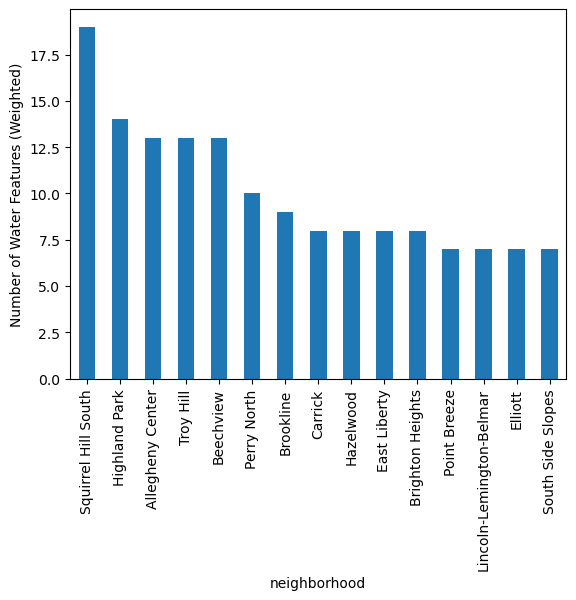

In [41]:
weighted_counts.head(15).plot(kind="bar", ylabel="Number of Water Features (Weighted)")

## Conclusion

As we can see, weighting the values has changed the rankings of the results which I beleive to be very interesting. It also tells us better which neighborhoods to avoid because CS majors need not be burdened by the mere idea of a shower.